In [1]:
# General notebook settings
import logging
import warnings

import pypsa

warnings.filterwarnings("error", category=DeprecationWarning)
# pandas<3.0.3 sets the `locs` attribute deprecated in matplotlib>=3.11
warnings.filterwarnings("ignore", message="The locs attribute was deprecated")
logging.getLogger("gurobipy").propagate = False
pypsa.options.params.optimize.log_to_console = False

# Time Series Aggregation

In this example, we are going to explore different ways to cluster the temporal resolution of PyPSA models, and what impact they have on the optimisation results and solving times. Using an hourly resolved variant of the [single-node capacity expansion example](./capacity-expansion-planning-single-node.ipynb), we will compare three different approaches to reduce the number of time steps in the model:

- **Sampling**: Selecting a subset of the given snapshots based on a given frequency,
- **Averaging**: Aggregating the snapshots by averaging them over a given frequency, and
- **Segmentation**: Clustering the snapshots into segments of a given frequency and using [`tsam`](https://tsam.readthedocs.io/en/latest/) library.

We start with the usual imports and loading the hourly resolved model.

In [2]:
import logging
import time

import pandas as pd

import pypsa

logging.getLogger().setLevel(logging.WARNING)


template_n = pypsa.Network(
    "https://tubcloud.tu-berlin.de/s/4ra3NKrLGzE42of/download/model-energy-hourly.nc"
)

/home/runner/work/PyPSA/PyPSA/pypsa/network/io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
INFO:pypsa.network.io:Retrieving network data from https://tubcloud.tu-berlin.de/s/4ra3NKrLGzE42of/download/model-energy-hourly.nc.


INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, links, loads, storage_units, stores


Since we also want to monitor the solving times, we will use a small utility function that wraps around the solving process and returns the seconds it took to solve the model:

In [3]:
def time_it(func, *args, **kwargs):
    """Time the execution of a function and return the elapsed time in seconds."""
    start_time = time.time()
    result = func(*args, **kwargs)
    elapsed_time = time.time() - start_time
    return result, elapsed_time


logging.getLogger().setLevel(logging.WARNING)

## Hourly Baseline

Additionally, we need a baseline model to compare aggregated models against. We will use the hourly resolved model for this.

In [4]:
n_hourly = template_n.copy()

_, s_hourly = time_it(n_hourly.optimize, solver_name="gurobi")
s_hourly

/tmp/ipykernel_8078/4243218267.py:4: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  result = func(*args, **kwargs)


Writing constraints.:   0%|          | 0/21 [00:00<?, ?it/s]

Writing constraints.:  90%|█████████ | 19/21 [00:00<00:00, 177.76it/s]

Writing constraints.: 100%|██████████| 21/21 [00:00<00:00, 170.81it/s]

Writing continuous variables.:   0%|          | 0/11 [00:00<?, ?it/s]

...

Read LP format model from file /tmp/linopy-problem-8ox17_4u.lp


Reading time = 0.17 seconds


obj: 192726 rows, 87606 columns, 372396 nonzeros


Set parameter LogToConsole to value 0


13.949392557144165

## Sampling

We will start with the sampling approach, which is the simplest one. We simply select every $N$-th snapshot from the model. The important part here is that we need to adjust the snapshot weightings accordingly, as each remaining snapshot now represents $N$ hours. We iterate over N from 2 to 11, i.e. from 2-hourly to 11-hourly resolved models.

In [5]:
sampling_n = {1: n_hourly}
sampling_s = {1: s_hourly}

for resolution in range(2, 12):
    n = template_n.cluster.temporal.downsample(resolution)

    _, s = time_it(n.optimize, solver_name="gurobi")

    sampling_n[resolution] = n
    sampling_s[resolution] = s

/tmp/ipykernel_8078/4243218267.py:4: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  result = func(*args, **kwargs)


Writing constraints.:   0%|          | 0/21 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 21/21 [00:00<00:00, 233.77it/s]

Writing continuous variables.:   0%|          | 0/11 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 11/11 [00:00<00:00, 457.18it/s]

...

Academic license 2537914 - for non-commercial use only - registered to l.___@tu-berlin.de


Read LP format model from file /tmp/linopy-problem-r9qask0p.lp


Reading time = 0.02 seconds


obj: 17540 rows, 7976 columns, 33888 nonzeros


Set parameter LogToConsole to value 0


## Averaging

The averaging approach also has equal snapshot durations, but instead of selecting data from every $N$-th snapshots, we average time series data for every $N$ snapshots. This means that the resulting model has $N$ times fewer snapshots, but each snapshot represents the average of $N$ original snapshots. Again, we need to adjust the snapshot weightings accordingly.

In [6]:
averaging_n = {1: n_hourly}
averaging_s = {1: s_hourly}

for resolution in range(2, 12):
    n = template_n.cluster.temporal.resample(f"{resolution}h")

    _, s = time_it(n.optimize, solver_name="gurobi")

    averaging_n[resolution] = n
    averaging_s[resolution] = s

/tmp/ipykernel_8078/4243218267.py:4: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  result = func(*args, **kwargs)


Writing constraints.:   0%|          | 0/21 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 21/21 [00:00<00:00, 246.44it/s]

Writing continuous variables.:   0%|          | 0/11 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 11/11 [00:00<00:00, 508.39it/s]

...

Academic license 2537914 - for non-commercial use only - registered to l.___@tu-berlin.de


Read LP format model from file /tmp/linopy-problem-2rgck634.lp


Reading time = 0.02 seconds


obj: 17540 rows, 7976 columns, 34205 nonzeros


Set parameter LogToConsole to value 0


## Segmentation

The segmentation approach is more complex. It uses a separate library called [`tsam`](https://tsam.readthedocs.io/en/latest/) to cluster the snapshots into segments of varying lengths. The sequence of snapshots is preserved as segments are only formed from neighbouring snapshots based on their similarity. For measuring similarity, it is advisable to normalise the time series data. This approach promises to capture the temporal patterns more effectively, as it can opt for higher resolution during periods of high variability and lower resolution during periods with low variability. The snapshot weightings are adjusted based on the number of snapshots in each segment.

In [7]:
segmentation_n = {1: n_hourly}
segmentation_s = {1: s_hourly}

for resolution in range(2, 12):
    # calculate number of segments equivalent to resolution
    segments = int(8760 / resolution)

    n = template_n.cluster.temporal.segment(segments)

    # run optimization
    _, s = time_it(n.optimize, solver_name="gurobi")

    segmentation_n[resolution] = n
    segmentation_s[resolution] = s

/tmp/ipykernel_8078/4243218267.py:4: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  result = func(*args, **kwargs)


Writing constraints.:   0%|          | 0/21 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 21/21 [00:00<00:00, 230.49it/s]

Writing continuous variables.:   0%|          | 0/11 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 11/11 [00:00<00:00, 500.62it/s]

...

Academic license 2537914 - for non-commercial use only - registered to l.___@tu-berlin.de


Read LP format model from file /tmp/linopy-problem-4z6smg0_.lp


Reading time = 0.01 seconds


obj: 17518 rows, 7966 columns, 34194 nonzeros


Set parameter LogToConsole to value 0


Now before we go ahead with the evaluation of the different approaches, let's quickly glance at the distribution of snapshot durations obtained from the segmentation approach for a resolution equivalent to a 3-hourly model. We can see quite some variability in the segment length.

<Axes: xlabel='snapshot duration [h]', ylabel='snapshots [number]'>

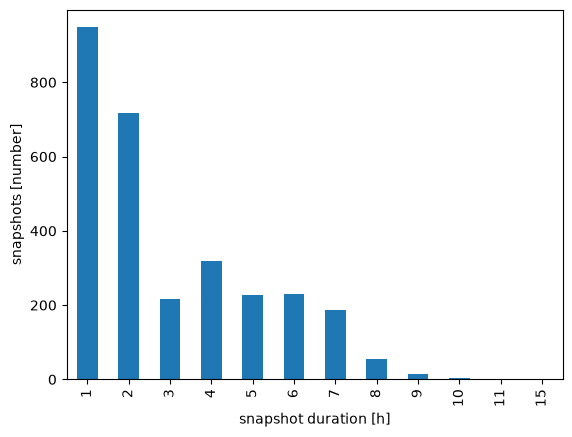

In [8]:
segmentation_n[3].snapshot_weightings.generators.value_counts().sort_index(
    ascending=True
).plot.bar(ylabel="snapshots [number]", xlabel="snapshot duration [h]")

## Evaluation

Let's start our evaluation with a look at the solving times. We can see that across all approaches, the solving times quickly decay, especially as we go from hourly to 2-hourly resolved models and decrease less substantially afterwards.

<Axes: xlabel='resolution [h]', ylabel='time [s]'>

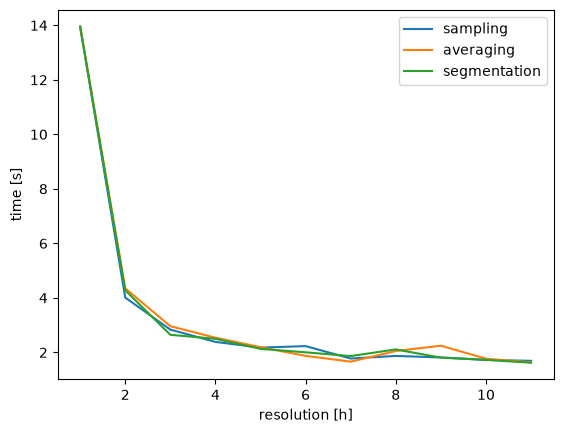

In [9]:
pd.Series(sampling_s).plot(label="sampling", legend=True)
pd.Series(averaging_s).plot(label="averaging", legend=True)
pd.Series(segmentation_s).plot(
    label="segmentation", ylabel="time [s]", xlabel="resolution [h]", legend=True
)

Furthermore, we compare the relative error in total system costs compared to the hourly resolved model. We can see how the segmentation approach remains more stable than the other two approaches, especially for lower resolutions. Even with 11-hourly equivalent resolution, the segmentation approach only has a relative error of -1% compared to the hourly resolved model (i.e. it appears to be 1% cheaper). Similar patterns can be observed for the relative error in the total installed capacity of solar and batteries, two technologies that are particularly sensitive to the temporal resolution of the model.

<Axes: xlabel='resolution [h]', ylabel='relative objective error [%]'>

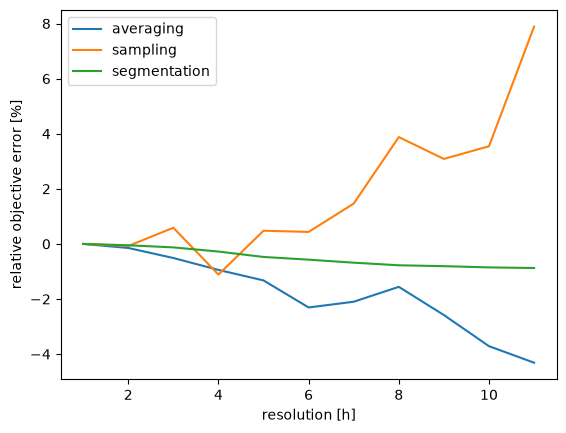

In [10]:
def tsc(n):
    return (n.statistics.capex().sum() + n.statistics.opex().sum()) / 1e9


pd.concat(
    [
        pd.Series({("sampling", res): tsc(n) for res, n in sampling_n.items()}),
        pd.Series({("averaging", res): tsc(n) for res, n in averaging_n.items()}),
        pd.Series({("segmentation", res): tsc(n) for res, n in segmentation_n.items()}),
    ]
).unstack(0).div(tsc(n_hourly)).sub(1).mul(100).plot(
    ylabel="relative objective error [%]", xlabel="resolution [h]", legend=True
)

<Axes: xlabel='resolution [h]', ylabel='relative solar capacity error [%]'>

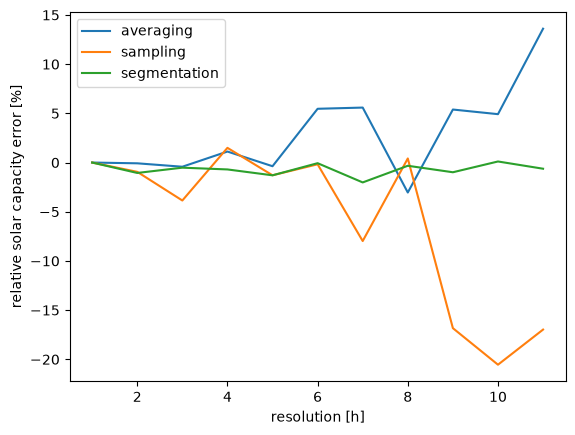

In [11]:
def solar(n):
    return n.generators.loc["solar", "p_nom_opt"]


pd.concat(
    [
        pd.Series({("sampling", res): solar(n) for res, n in sampling_n.items()}),
        pd.Series({("averaging", res): solar(n) for res, n in averaging_n.items()}),
        pd.Series(
            {("segmentation", res): solar(n) for res, n in segmentation_n.items()}
        ),
    ]
).unstack(0).div(solar(n_hourly)).sub(1).mul(100).plot(
    ylabel="relative solar capacity error [%]", xlabel="resolution [h]", legend=True
)

<Axes: xlabel='resolution [h]', ylabel='relative battery capacity error [%]'>

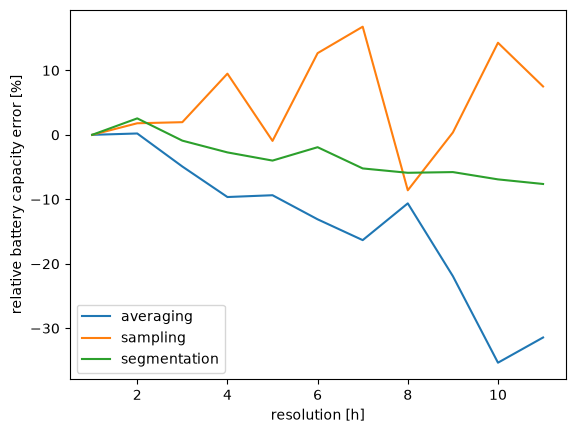

In [12]:
def battery(n):
    return n.storage_units.loc["battery storage", "p_nom_opt"]


pd.concat(
    [
        pd.Series({("sampling", res): battery(n) for res, n in sampling_n.items()}),
        pd.Series({("averaging", res): battery(n) for res, n in averaging_n.items()}),
        pd.Series(
            {("segmentation", res): battery(n) for res, n in segmentation_n.items()}
        ),
    ]
).unstack(0).div(battery(n_hourly)).sub(1).mul(100).plot(
    ylabel="relative battery capacity error [%]", xlabel="resolution [h]", legend=True
)